# Phase 3: What Drives Low Hotel Review Scores?

INFO 4360 course project, Phase 3 (final analysis) | Braxton Turner

Problem. A hotel group's guest experience manager needs to know which complaints are behind low review scores, so they can fix the right things first. It matters because a drop in review scores pushes a hotel down in booking-site search results and costs bookings, and no one can read thousands of reviews a month to find out which problems are behind it. The data is 19,998 Booking.com reviews of 1,434 hotels in six European cities (a stratified sample of the 515,738-review file). Each guest writes what they liked and disliked in two separate boxes.

#### What this notebook covers
0. Recap of the Phase 2 findings.
1. Top words revisited, with the Phase 2 feedback applied (negations dropped, lemmas, counts vs. TF-IDF).
2. Claude labeling of every review: complaint categories (negative box) and praise categories (positive box), sent through the Batch API. Prompts, sample outputs, tokens and cost.
3. Label quality: validation checks, evidence quotes, a repeat-request consistency test, agreement with the keyword lexicon, and a 100-review hand check. Trade-offs: when Claude was worth it.
4. Models M0 to M3: how much of the score the named categories explain compared with TF-IDF words (5-fold cross-validation). Predicting a low score: majority baseline, accuracy, F1, confusion matrix, train vs. test.
5. The fix list: points lost per 100 reviews for each complaint, and what earns points.
6. Business vs. leisure travelers, the six cities, and a bias check: native-English vs. other reviewers.
7. Robustness: review length, a low-score logistic model, hotel fixed effects, stability across folds.
8. Key findings, business implications and limits.
9. Ethical and privacy considerations.
10. AI usage log.

#### Changes since Phase 2 (from the feedback)
- Top words: "no" and "not" are left out of single-word lists, words are lemmatized so "room" and "rooms" count together, and TF-IDF is shown next to raw counts (Section 1).
- All 19,998 reviews are labeled instead of a 3,000-review sample. With 1,434 hotels, 3,000 reviews would be about 2 per hotel, so hotel effects would absorb almost everything. Now it is about 14 per hotel, which makes the hotel fixed-effects check (Section 7) meaningful. Cost with the Batch API: about $2.40 estimated before sending.
- The batch was tested on 100 reviews first, and the script never resends a request that already has a saved result (`scripts/run_batch.py`). The notebook itself never calls the API; it only reads `data/labels_final.jsonl`.
- The prompt has rules for the overlapping definitions found in the Phase 2 test ("two singles pushed together", "air con broken in the bar").
- Because the sample keeps the real city x trip-type shares, no sample weights are needed for "how often".

## 0. Setup

In [1]:
# Step 0: Imports. Reusable functions live in src/ so the notebook stays readable.
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repo root, so `import src...` works from notebooks/

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import cohen_kappa_score

from src.data import load_reviews
from src.preprocessing import TOP_WORD_STOP, load_lemmatizer, lemmatize
from src.complaints import KEYWORDS
from src import batch_labels as bl
from src import models as m
from src import handcheck as hc

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
LOW, HIGH = "#c0392b", "#2c7fb8"            # low-score and high-score reviews (same as Phase 2)
BUSINESS, LEISURE = "#e08a2e", "#2c7fb8"    # trip types (orange / blue: safe for color blindness)

In [2]:
# Step 0.1: Load the sample and the NER-cleaned text (built once by `python scripts/run_batch.py prepare`;
# the same text is what was sent to Claude, so staff and hotel names never left the computer)
df = load_reviews()
clean = bl.load_clean_text()
assert len(df) == len(clean) == 19_998 and (df.review_id.to_numpy() == clean.review_id.to_numpy()).all()
df = df.merge(clean, on="review_id", validate="one_to_one")
df.index = df.review_id
print(f"{len(df):,} reviews | {df.Hotel_Name.nunique():,} hotels | {df.has_neg.sum():,} with a complaint | "
      f"{df.has_pos.sum():,} with praise | {len(df) / df.Hotel_Name.nunique():.1f} reviews per hotel")

19,998 reviews | 1,434 hotels | 13,738 with a complaint | 18,506 with praise | 13.9 reviews per hotel


## Recap: what Phase 2 found

Phase 2 (`notebooks/phase2_exploration.ipynb`) explored the same 19,998 reviews. The findings that shaped this notebook:
- Scores are skewed high: mean 8.40, and only 17.1% of reviews are below 7. Business travelers give a low score far more often than leisure travelers (24.6% vs. 15.5%), and nationality alone moves the average by almost 0.9 points (UAE 7.88 vs. US 8.77). So trip type, city and nationality are controls in every model here, and the fix list is checked separately for business and leisure guests.
- 31% of negative boxes are placeholders ("No Negative", "nothing", "everything was perfect"). They are treated as empty, so they are not counted as complaints.
- Length is a strong signal on its own: low-score complaints have a median of 22 words vs. 5. A word model partly measures how much a guest complained, so Section 7 checks the fix list with a length control.
- Words alone are a weak fix list: TF-IDF picks out intensity words ("poor", "bad", "rude") that don't say what to fix, and VADER sentiment agrees only weakly with the score (r = 0.28 on the complaint box), because 30% of complaints have no emotional words ("room small", "no kettle").
- LDA found ten complaint topics that mostly matched my categories and showed two gaps (hotel facilities, and star rating / wrong room type), which became the `facilities` category and part of `checkin` and `value`.
- spaCy NER removes staff and hotel names before any text goes to the API, word by word, because removing every entity would also delete complaint words like "Breakfast" and "Wifi".
- A 12-review Claude test showed that Claude handles meaning better than keywords ("not clean", praise written in the complaint box), and that its errors come from overlapping definitions. That led to the category rules in the final prompt.

## 1. Top words revisited (Phase 2 feedback)

The Phase 2 feedback: "no" and "not" add little information in a top-word list, "room" and "rooms" should be combined, and with TF-IDF "room" would probably drop. Three changes:
1. Lemmatize the negative box with spaCy, so "rooms" becomes "room" and "beds" becomes "bed".
2. Leave negations out of single-word lists (`TOP_WORD_STOP`). They stay in for bigrams and the TF-IDF models, where "not clean" needs the "not".
3. Rank words two ways in low-score complaints: share of reviews that use the word (counts), and mean TF-IDF weight. TF-IDF lowers words that appear everywhere.

In [3]:
# Step 1: Lemmatize the negative box (about a minute)
nlp_lemma = load_lemmatizer()
has_neg = df[df.has_neg == 1].copy()
has_neg["neg_lemma"] = lemmatize(has_neg.neg_clean, nlp_lemma)
print(has_neg[["neg_clean", "neg_lemma"]].head(3).to_string())

                                                                                                                      neg_clean                                                                                                         neg_lemma
review_id                                                                                                                                                                                                                                        
0          Very poor TV channels and few channels also old TV set Club room food is vey poring and very limited not recommended  very poor tv channel and few channel also old tv set club room food be vey poring and very limited not recommend
1                                                                                       rooms are old no variety of food no spa                                                                             room be old no variety of food no spa
2                               

In [4]:
# Step 1.1: Top 15 words in LOW-score complaints, three ways
low = has_neg[has_neg.Low_Score == 1]

def share_top(texts, n=15):
    vec = CountVectorizer(stop_words=TOP_WORD_STOP, min_df=5)
    X = vec.fit_transform(texts)
    return pd.Series(np.asarray((X > 0).mean(axis=0)).ravel(), index=vec.get_feature_names_out()).nlargest(n)

def tfidf_top(texts, n=15):
    vec = TfidfVectorizer(stop_words=TOP_WORD_STOP, min_df=5, sublinear_tf=True)
    X = vec.fit_transform(texts)
    return pd.Series(np.asarray(X.mean(axis=0)).ravel(), index=vec.get_feature_names_out()).nlargest(n)

before = share_top(low.neg_clean)        # Phase 2 style words, negations dropped
counts = share_top(low.neg_lemma)        # + lemmas
tfidf = tfidf_top(low.neg_lemma)         # + TF-IDF weighting
pd.DataFrame({"words (no negations)": [f"{w} {v:.0%}" for w, v in before.items()],
              "lemmas, share of reviews": [f"{w} {v:.0%}" for w, v in counts.items()],
              "lemmas, mean TF-IDF": [f"{w} {v:.3f}" for w, v in tfidf.items()]},
             index=range(1, 16))

,words (no negations),"lemmas, share of reviews","lemmas, mean TF-IDF"
1,room 49%,room 57%,room 0.079
2,hotel 26%,hotel 27%,small 0.042
3,staff 19%,staff 19%,hotel 0.040
4,small 17%,small 18%,staff 0.037
5,breakfast 15%,breakfast 15%,breakfast 0.031
6,rooms 14%,bed 15%,bed 0.029
7,bed 12%,bathroom 11%,bathroom 0.022
8,bathroom 10%,stay 11%,clean 0.021
9,poor 9%,night 10%,poor 0.021
10,like 9%,time 9%,service 0.020


In [5]:
# Where does "room" rank under each method? (full ranking, not just the top 15)
def rank_of(series_fn, texts, word):
    full = series_fn(texts, n=10_000)
    return int((full.index == word).argmax()) + 1 if word in full.index else None

print("'room' rank by share of reviews (lemmas):", rank_of(share_top, low.neg_lemma, "room"))
print("'room' rank by mean TF-IDF (lemmas):     ", rank_of(tfidf_top, low.neg_lemma, "room"))
print("'rooms' still separate after lemmas?      ", "rooms" in share_top(low.neg_lemma, n=10_000).index)

'room' rank by share of reviews (lemmas): 1
'room' rank by mean TF-IDF (lemmas):      1
'rooms' still separate after lemmas?       False


What I see. Lemmatizing did what the feedback expected: "rooms" (14% of low-score complaints) merged into "room", which went from 49% to 57%, and "bed" moved up from 12% to 15% once "beds" was counted with it. With "no" and "not" left out, every word in the list is a content word. TF-IDF did not push "room" down: it is still first (0.079), but its lead shrinks, and the words that rise are the ones that say what was wrong: "small" moves from 4th to 2nd, and "clean", "expensive" and "bad" enter the top 15, while vague words like "time", "like" and "pay" drop out. "room" stays on top because it is in more than half of the low-score complaints and is often repeated within one review, so it is a topic word rather than a problem word. That is why the fix list uses categories ("room_size", "cleanliness", "maintenance") instead of single words.

## 2. Claude labeling of every review

Each non-empty box is one request: the negative box gets the 14 complaint categories from Phase 2, and the positive box gets 13 praise categories. Claude Haiku 5.5 at low effort, with a JSON schema that only allows these category names, and an evidence quote for every label. All requests went through the Batch API (half price) with `scripts/run_batch.py`:
1. `dry-run` built the requests and estimated the cost without sending anything.
2. A test batch of 100 reviews (50 low, 50 high score) was sent and checked first.
3. The full batch sent everything else. Requests with a saved result are never built again, so nothing was sent twice.
4. 50 negative boxes were sent a second time on purpose, to measure consistency (Section 3.3).

In [6]:
# Step 2: The two prompts (negative box shown in full; the positive box uses the same template)
print(bl.make_prompt("neg", "(negative review text goes here)"))
print("\nPraise categories:", ", ".join(bl.PRAISE))

You are labeling hotel guest reviews for a hotel group's guest experience manager.
Below is what one guest wrote in the "What did you dislike?" box. Tag every complaint category that applies.

Categories:
- cleanliness: dirt, stains, dust, hair, bad smells, mould, or poor housekeeping
- noise: noise from the street, other guests, thin walls, construction, or the building
- staff: rude, unhelpful, or slow staff, or poor service from reception or other staff
- room_size: the room or bathroom is small, cramped, or has no space for luggage
- breakfast: breakfast, restaurant, or other food and drink served at the hotel
- facilities: hotel facilities missing, closed, or extra cost: bar, pool, gym, spa, minibar, parking, kettle
- value: price too high for what you get, unexpected charges or extra fees, or not up to the hotel's star rating
- maintenance: broken, worn, or outdated things: shower, plumbing, lift, furniture, decor
- temperature: room too hot or too cold, air conditioning or heati

In [7]:
# Step 2.1: Which labels does this run use?
# FINAL = the Claude labels cover every non-empty box. Before the final run, the models run on the
# keyword lexicon instead so the code can be tested; nothing from that mode is reported.
records = bl.read_labels(bl.LABELS_PATH)
label_checks = bl.validate_labels(records, df, clean) if records else None
# Allow at most 0.1% of boxes missing (a missing box counts as "no label")
n_missing = int(label_checks.detail.iloc[1].split("; ")[1].split()[0].replace(",", "")) if records else None
FINAL = label_checks is not None and label_checks.result.iloc[[0, 2]].eq("PASS").all() and n_missing <= 32

if FINAL:
    neg_flags = bl.label_flags(records, df, "neg")
    pos_flags = bl.label_flags(records, df, "pos")
    print(f"Using Claude labels: {len(records):,} saved results, {n_missing} boxes missing")
    display(label_checks)
else:
    neg_flags, pos_flags = m.keyword_stand_in(clean)
    print("DEVELOPMENT MODE: data/labels_final.jsonl is missing or incomplete "
          f"({len(records):,} results). The models below use KEYWORD flags as a stand-in. Do not report these numbers.")
flags = m.flag_matrix(neg_flags, pos_flags, df.index)
print(flags.shape[1], "flag columns")

Using Claude labels: 32,290 saved results, 0 boxes missing


,check,result,detail
0,No custom_id saved twice,PASS,"32,290 records"
1,Every non-empty box has a successful label,PASS,"32,240 of 32,240 boxes; 0 missing"
2,No request sent for an empty box,PASS,0 extra
3,Every response finished normally (end_turn),PASS,0 cut off or refused
4,Every label uses a defined category,PASS,0 unknown categories
5,At least 98% of evidence quotes appear in the review,PASS,"99.9% of 75,063 quotes"


27 flag columns


In [8]:
# Step 2.2: Cost (only results from the API carry a cost)
if records:
    cost = pd.DataFrame(records)
    print(f"{len(cost):,} requests | {cost.input_tokens.sum():,.0f} input and {cost.output_tokens.sum():,.0f} output tokens | "
          f"${cost.cost_usd.sum():.2f} total, ${cost.cost_usd.mean() * 2:.5f} per review (both boxes) with the Batch discount")
print("Estimate before sending:", bl.estimate_cost(bl.build_requests(df, clean, repeats=bl.consistency_ids(df))))

32,290 requests | 35,659,964 input and 2,783,493 output tokens | $2.48 total, $0.00015 per review (both boxes) with the Batch discount


Estimate before sending: {'requests': 32290, 'input_tokens_est': 16287463, 'output_tokens_est': 6458000, 'cost_usd_est': 2.43}


In [9]:
# Step 2.3: Sample outputs: three random complaints, the text that was sent, and what Claude returned
neg_records = {r["review_id"]: r for r in records if r["box"] == "neg" and not r["repeat"]}
for rid in df[df.has_neg.astype(bool)].sample(3, random_state=7).review_id:
    print(f"Review {rid} | score {df.at[rid, 'Reviewer_Score']} | {df.at[rid, 'City']}, {df.at[rid, 'Trip_Type']}")
    print("  Sent to Claude:", df.at[rid, "neg_clean"][:500])
    for lab in neg_records[rid]["labels"]:
        print("  ->", f"{lab['category']:12s}", "evidence:", repr(lab["evidence"]))
    print()

Review 6950 | score 9.6 | London, Leisure
  Sent to Claude: It s a very small thing but the coffee at breakfast was not the best This in no way spoilt out stay
  -> breakfast    evidence: 'the coffee at breakfast was not the best'

Review 7724 | score 7.5 | London, Leisure
  Sent to Claude: Our room had an accessible shower which meant the whole bathroom floor was wet after showering Missed having a bath to soak in
  -> maintenance  evidence: 'Our room had an accessible shower which meant the whole bathroom floor was wet after showering'
  -> other        evidence: 'Missed having a bath to soak in'

Review 12547 | score 8.8 | London, Leisure
  Sent to Claude: Didn t like bed linen or pillows Not good quality
  -> bed_comfort  evidence: 'Didn t like bed linen or pillows Not good quality'



## 3. Label quality

Four checks from the Phase 2 plan (Section 4.6), plus pass/fail validation in the same style as Section 1.7 of Phase 2.

In [10]:
# Step 3.1: Pass/fail checks on the label file. Before the final run this runs on the 40 pilot reviews
# I labeled in Claude Code (data/pilot_labels.jsonl) to test the checks themselves.
if FINAL:
    check_records, check_df = records, df
else:
    check_records = bl.read_labels(bl.PILOT_PATH)
    check_df = df[df.review_id.isin({r["review_id"] for r in check_records})]
    print(f"(pilot labels: {len(check_df)} reviews)")
bl.validate_labels(check_records, check_df, clean)

,check,result,detail
0,No custom_id saved twice,PASS,"32,290 records"
1,Every non-empty box has a successful label,PASS,"32,240 of 32,240 boxes; 0 missing"
2,No request sent for an empty box,PASS,0 extra
3,Every response finished normally (end_turn),PASS,0 cut off or refused
4,Every label uses a defined category,PASS,0 unknown categories
5,At least 98% of evidence quotes appear in the review,PASS,"99.9% of 75,063 quotes"


In [11]:
# Step 3.2: Evidence check: does every quote appear word for word in the review?
ev = bl.evidence_table(check_records, clean)
print(f"{ev.found.mean():.1%} of {len(ev):,} quotes found in the review")
ev.groupby(["box", "category"]).found.agg(["size", "mean"]).unstack(0).round(3).head(30)

99.9% of 75,063 quotes found in the review


size            mean       
box             neg      pos    neg    pos
category                                  
bed_comfort  1007.0   3155.0  0.998  1.000
breakfast    2577.0   4297.0  0.999  1.000
checkin      1608.0   1077.0  0.996  0.996
cleanliness  1718.0   3155.0  0.998  0.997
design          NaN   2556.0    NaN  1.000
facilities   2560.0   2908.0  0.998  0.999
location     1124.0  10347.0  0.996  1.000
maintenance  3183.0      NaN  0.999    NaN
noise        1731.0      NaN  0.997    NaN
other        1427.0   2187.0  0.996  0.998
quiet           NaN   1142.0    NaN  0.997
room            NaN   6951.0    NaN  0.999
room_size    2403.0      NaN  0.998    NaN
staff        2471.0   9209.0  1.000  0.999
temperature  1111.0      NaN  1.000    NaN
value        3113.0    969.0  0.997  1.000
wifi          682.0    395.0  1.000  0.997

In [12]:
# Quotes that were NOT found: paraphrases, or labels with no real basis?
ev[~ev.found].head(15)

,review_id,box,category,evidence,found
632,8529,pos,checkin,i was upgraded to penthouse,False
1529,10920,pos,cleanliness,clean room,False
1928,1665,neg,breakfast,No breakfast option | No room service | Poor choice of tea coffee,False
1929,1665,neg,facilities,No spa facilities | Facilities in room basic for example shower cap refreshments no mini bar etc | Where a...,False
3470,2059,neg,cleanliness,We never had our room serviced at all,False
4787,13620,neg,maintenance,No grab handle and shower tray gets quite slippy in use,False
5390,4078,pos,staff,,False
5962,6549,pos,location,there is a line a 2 minute walk away that was perfect,False
6470,18019,neg,checkin,the booking was not honored,False
6902,1220,pos,cleanliness,clean room,False


In [13]:
# Step 3.3: Consistency: 50 negative boxes were sent twice. Same set of categories both times?
cons = bl.consistency_table(records)
if len(cons):
    print(f"{cons.same.mean():.0%} of {len(cons)} repeated reviews got exactly the same categories")
    display(cons[~cons.same])
else:
    print("No repeated requests yet (they are part of the full batch).")

94% of 50 repeated reviews got exactly the same categories


,review_id,first,second,same
6,10530,"[breakfast, checkin, staff, value]","[checkin, staff, value]",False
39,2042,"[other, room_size]","[maintenance, room_size]",False
44,13303,"[other, room_size]","[cleanliness, location, room_size]",False


In [14]:
# Step 3.4: Agreement with the keyword lexicon (Cohen's kappa per category). Low agreement is not
# automatically Claude's fault: the lexicon counts "clean" in "not clean". Big gaps show where to look.
kw_neg, _ = m.keyword_stand_in(clean)
claude_neg = bl.label_flags(check_records, check_df, "neg")
kw = kw_neg.loc[claude_neg.index]
agree = pd.DataFrame({
    "Claude share": claude_neg.mean(), "keyword share": kw.mean(),
    "kappa": [cohen_kappa_score(claude_neg[c], kw[c]) if c in kw else np.nan for c in claude_neg],
}).drop(index="other")
agree.round(2).sort_values("kappa")

,Claude share,keyword share,kappa
staff,0.10,0.12,0.52
location,0.05,0.05,0.58
temperature,0.05,0.06,0.59
noise,0.08,0.06,0.61
bed_comfort,0.05,0.07,0.67
maintenance,0.13,0.09,0.73
checkin,0.07,0.05,0.74
value,0.14,0.10,0.74
cleanliness,0.07,0.05,0.77
breakfast,0.12,0.13,0.82


In [15]:
# Step 3.5: Hand check (100 negative boxes, blind: the sheet does not show Claude's labels).
# First run after the final labels: writes data/handcheck_100.csv. I fill it in (1 = category present),
# then re-run this cell to score it.
SHEET = Path.cwd().parent / "data" / "handcheck_100_done.csv"   # my answers (blank sheet: handcheck_100.csv)
if not FINAL:
    print("Hand check waits for the final labels.")
elif not SHEET.exists():
    hc.make_sheet(records, df, clean, SHEET)
    print(f"Wrote {SHEET.name}: fill in the category columns, then re-run this cell.")
elif hc.read_sheet(SHEET)[list(bl.COMPLAINTS)].to_numpy().sum() == 0:
    print(f"{SHEET.name} exists but is still empty.")
else:
    hc_table, hc_overall, hc_dis = hc.score_sheet(SHEET, records, df)
    print({k: round(v, 3) for k, v in hc_overall.items()})
    display(hc_table.round(2))

{'precision (all labels)': np.float64(0.636), 'recall (random part)': np.float64(0.639), 'reviews where every category matches': np.float64(0.38), 'random reviews': 44, 'agreement on yes/no decisions (random part)': np.float64(0.901), "Cohen's kappa (random part)": 0.577, 'every category matches (random part)': np.float64(0.455)}


,category,Claude tagged,I tagged,both,precision,recall (random part)
0,cleanliness,15,10,7,0.47,0.25
1,noise,14,8,8,0.57,1.00
2,staff,16,14,13,0.81,1.00
3,room_size,24,27,19,0.79,0.54
4,breakfast,21,20,19,0.90,1.00
5,facilities,18,8,4,0.22,0.50
6,value,23,19,17,0.74,1.00
7,maintenance,23,23,14,0.61,0.57
8,temperature,14,12,11,0.79,1.00
9,wifi,4,4,4,1.00,NaN


In [16]:
# Every disagreement between me and Claude, to see which definitions cause them
if FINAL and SHEET.exists() and "hc_dis" in globals():
    display(hc_dis.sort_values(["category", "who"]))

,review_id,category,who,Claude's evidence,complaint_text
37,3497,bed_comfort,Claude only,The bed was uncomfortable,There was no air con because as the receptionist explained it was Spring time and air con was too expensiv...
52,5732,bed_comfort,Claude only,Uncomfortable sleep,Rooms were very cold and it was difficult to get any warmth from ac unit Uncomfortable sleep Checkout poor...
63,7594,bed_comfort,Claude only,Uncomfortable dining chairs,Uncomfortable dining chairs and very small shower room for single use Had to go into bedroom to finish off...
75,13870,bed_comfort,Claude only,the bed is tiny,the bed is tiny and the room was cold and not enough blanket and the service wasnt good
16,13701,bed_comfort,me only,,Not very much We would gladly stay here again On the Sunday morning there was a small hiccup at breakfast ...
...,...,...,...,...,...
45,13766,value,Claude only,for the quality of the food it is not cheap,I made a special request for a room on a low floor for medical reasons and asked the person on reservation...
101,10299,value,Claude only,Generally not up to Best Western standards,Bed had seen better days Water pressure so low we couldn t take a shower Car parking limited and on a firs...
120,13492,value,Claude only,Not a superior bathroom either,Superior label for the room is a joke It was small with a standard size bed Not a superior bathroom either...
61,3628,value,me only,,We could have done with more drinking water and tea bags


What I see.
- The labels pass the automatic checks. 32,282 of 32,290 requests came back complete; 8 very long reviews hit the 1,024-token answer limit and were re-sent with a higher limit. Every label uses a defined category, and 99.9% of the 75,063 evidence quotes appear word for word in the review (some of the few misses are several quotes joined with " | ", which the word-for-word check cannot match).
- Consistency: 47 of the 50 reviews sent twice (94%) got exactly the same categories. The 3 changes are borderline extras: `other` became `maintenance` or `cleanliness` for the same sentence, and one review lost a `breakfast` tag on the second run.
- Agreement with the keyword lexicon is moderate to high (kappa 0.51 to 0.96). It is lowest for staff (0.51), likely because the lexicon counts every mention of "staff" or "reception", including praise written inside the complaint box ("staff were lovely but..."), which Claude does not tag as a complaint.
- In the 100-review test, Claude tagged slightly more than my pilot labels (101 vs. 91 tags), mostly loose `value` and `checkin` tags. The hand check below measures this per category.
- Hand check (100 complaints, labeled blind in Word, then compared): Claude's precision is 64% and its recall is 64% (recall on the 44 randomly picked reviews); 38% of reviews match on every category. Agreement rate on the 44 randomly picked reviews: we agree on 90% of the 616 yes/no decisions (review x category), with Cohen's kappa 0.58 (moderate), and 45% of them match on every category. Claude tags more than I do (220 vs. 194 tags). Precision is high for the categories at the top of the fix list: breakfast 90%, staff 81%, room size 79%, temperature 79%, value 74%. It is lowest for facilities (22%) and check-in (31%), where Claude stretches the definitions to missing amenities (kettle, bathrobes, TV) and to "wrong room type / no upgrade". Cleanliness (47%) and bed comfort (50%) are judgment calls. My own extra tags are mostly `other` (13 of 54), complaints I did not think fit any category.
- Caveat: these are my labels, done once by one person, and they include a few likely slips of my own (for example location typed for a broken air conditioner), so 64% is a lower bound on agreement. The five complaints at the top of the fix list are among the most reliably labeled, so the main conclusion holds; the facilities and check-in estimates should be read with care.

### 3.6 Trade-offs: when was Claude worth it?

Worth it:
- Meaning, not words. The keyword lexicon counts "clean" in "not clean" and "staff" in "staff were lovely but...". Claude reads the sentence, which is why agreement with the lexicon is lowest for staff (kappa 0.51), the most important complaint.
- Several complaints per review, each with a quote. Guests often list two or three problems, and the quotes made every label checkable (99.9% found word for word).
- Cost and time were small: $2.48 for 32,290 boxes with the Batch API (half price), about 2.8 million output tokens, and about an hour of waiting. Labeling 20,000 reviews by hand would take weeks.

Could have been cheaper or simpler:
- For categories with clear words (Wi-Fi, breakfast, temperature) the free keyword lexicon agrees with Claude well (kappa up to 0.96). Claude mattered most for staff, value, maintenance and check-in.
- If the only goal were predicting the score, TF-IDF needs no labels at all and explains slightly more (Section 4). It just does not produce a fix list a manager can act on.
- The same category definitions are sent with every request: about 1,100 input tokens per request, and input is 93% of all tokens. Prompt caching or shorter definitions would cut the cost further.

Is agreement high enough to build on? The guideline is to revise the prompt and rerun if agreement is low. On the random sample we agree on 90% of yes/no decisions (kappa 0.58). Overall precision is 64%, but it is 74 to 90% for the five complaints at the top of the fix list, and the labels are used as features in a regression, not as targets for a classifier, so a wrong label weakens a coefficient rather than teaching a model a mistake. The two weak categories (facilities 22%, check-in 31%) are reported with a warning instead of as findings. The next step would be to tighten those two definitions (for example "a missing amenity in the room is not a facilities complaint") and rerun only those boxes, for about $1.

## 4. How much do the categories explain? Models M0 to M3

All four models use the same five folds and the same controls (city, trip type, top 15 nationalities, nights, review quarter). The score is the outcome.

| Model | Features | Purpose |
|---|---|---|
| M0 | controls only | baseline |
| M1 | controls + complaint and praise flags (OLS) | the fix list |
| M2 | controls + TF-IDF on both boxes (ridge) | benchmark: how much can the words explain? |
| M3 | M1 + M2 (ridge) | what the categories miss |

Out-of-sample R^2 is the fair comparison: in-sample R^2 always rises with more features. The key number is the share of the explainable variation that the named categories capture: (R^2 M1 - R^2 M0) / (R^2 M2 - R^2 M0).

In [17]:
# Step 4: Cross-validated comparison (about 5 minutes: TF-IDF + ridge on each fold)
X_controls = m.controls(df)
fold_results, summary, share = m.compare_models(df, X_controls, flags)
print(f"The categories capture {share:.0%} of what the TF-IDF words explain beyond the controls")
summary.round(3)

The categories capture 95% of what the TF-IDF words explain beyond the controls


,R2_mean,R2_sd,RMSE_mean,features
model,,,,
M0 controls,0.025,0.004,1.614,34.0
M1 + categories,0.472,0.014,1.188,61.0
M2 + TF-IDF words,0.494,0.019,1.163,2941.6
M3 categories + words,0.540,0.015,1.109,2968.6


What I see. The named categories explain almost as much as the words. Controls alone explain 2.5% of the variation in scores (out-of-sample R^2 0.025). Adding the 27 complaint and praise flags raises that to 0.472, while about 2,900 TF-IDF word features reach 0.494. So the categories capture 95% of what the words explain beyond the controls, with 1% as many features, and every one of them is something a manager can act on. Combining both (M3) reaches 0.540, so the words still carry some extra information, mostly intensity ("worst", "never again") that a yes/no category does not measure. The fold-to-fold spread is small (SD about 0.015), so the comparison is stable.

### 4.1 Predicting a low score (Path A metrics)

The fix list explains the score, but the same features can also predict whether a review will be low (below 7). Here the reviews are split once into 80% training and 20% test, keeping the 17% share of low scores in both. Every model is compared with the majority-class baseline, which always predicts "not low". Because only 17% of reviews are low, accuracy alone flatters a model, so F1 for the low class is reported too.

In [18]:
# Step 4.1: Low-score classifier: baseline vs. controls vs. categories vs. TF-IDF words (logistic regression)
clf_table, clf_cm, clf_coefs = m.classify_low_score(df, X_controls, flags)
print("Majority-class baseline accuracy:", f"{1 - df.Low_Score.mean():.1%}")
display(clf_table.round(3))
print("Confusion matrix, controls + categories, test set (4,000 reviews):")
clf_cm

Majority-class baseline accuracy: 82.9%


,train accuracy,train F1,test accuracy,test F1,test precision,test recall
model,,,,,,
Majority class (always 'not low'),0.829,0.000,0.829,0.000,0.000,0.000
Controls only,0.829,0.000,0.829,0.000,0.000,0.000
Controls + categories,0.878,0.564,0.872,0.536,0.708,0.430
"Controls + categories, balanced weights",0.812,0.599,0.804,0.582,0.458,0.798
Controls + TF-IDF words,0.904,0.654,0.873,0.531,0.718,0.422


Confusion matrix, controls + categories, test set (4,000 reviews):


,predicted: not low,predicted: low
actual: not low,3196,121
actual: low,389,294


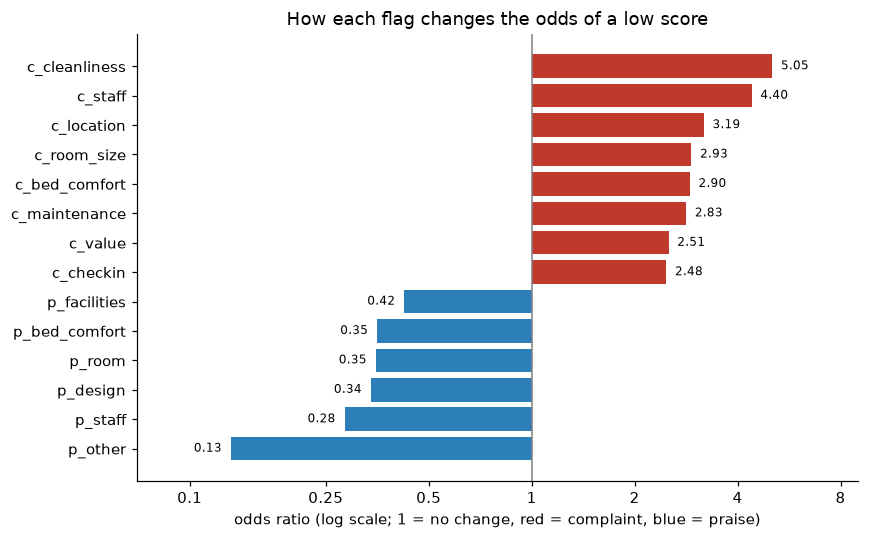

In [19]:
# Which features matter: odds ratios of the complaint and praise flags (controls + categories model)
odds = np.exp(pd.concat([clf_coefs.head(6), clf_coefs.tail(8)]))
fig, ax = plt.subplots(figsize=(8, 5))
# Bars start at 1 (no change): complaints grow right, praise grows left
ax.barh(odds.index, odds.values - 1, left=1, color=[LOW if v > 1 else HIGH for v in odds.values])
ax.axvline(1, color="grey", lw=1)
ax.set_xscale("log")
ax.set_xlim(0.07, 9)
ticks = [0.1, 0.25, 0.5, 1, 2, 4, 8]
ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax.minorticks_off()
ax.set(title="How each flag changes the odds of a low score",
       xlabel="odds ratio (log scale; 1 = no change, red = complaint, blue = praise)")
for y_pos, v in enumerate(odds.values):
    ax.text(v * (1.06 if v > 1 else 0.94), y_pos, f"{v:.2f}", va="center", ha="left" if v > 1 else "right", fontsize=8)
plt.tight_layout()
plt.show()

What I see.
- The majority baseline is 82.9% accurate with an F1 of 0 for low scores: it never finds a single low review. Controls alone (city, trip type, nationality, nights, quarter) do no better; they shift the average but never push a review over the line.
- Controls + categories reach 87.2% test accuracy and an F1 of 0.54 for low scores. When the model says "low" it is right 71% of the time (precision), but it finds only 43% of the low reviews (recall). The confusion matrix shows why: 389 low reviews are predicted "not low", against 121 false alarms.
- With balanced class weights the model finds 80% of low reviews (recall 0.80), at the cost of more false alarms (precision 0.46) and lower accuracy (80.4%). For a manager who wants to catch unhappy guests, that trade is probably worth it; F1 rises to 0.58.
- Overfitting: the categories model scores almost the same on training and test data (accuracy 87.8% vs. 87.2%, F1 0.56 vs. 0.54), so it is not overfitting. The TF-IDF model, with about 2,900 word features, drops from 90.4% to 87.3% and from F1 0.65 to 0.53: it memorizes training reviews and ends up no better than the 27 categories on new ones.
- Why recall is limited: a score is a guest's overall judgment. Many low scores come with short or vague complaints, and some have no complaint at all, so no text model can see them. This is the same ceiling as the R^2 of about 0.5 in Section 4.
- Features that matter: a cleanliness complaint multiplies the odds of a low score by about 5, and a staff complaint by about 4.4, then location, room size, bed comfort and maintenance (about 3). On the praise side, praising the staff cuts the odds of a low score by about 70%. The same complaints top the fix list, so prediction and explanation agree.

## 5. The fix list

M1 fit on all reviews, standard errors clustered by hotel (reviews of the same hotel are not independent). Each complaint coefficient is the points lost when a guest raises that complaint, holding the other complaints, the praise and the controls fixed. Points lost x how often it happens = expected points lost per 100 reviews.

In [20]:
# Step 5: Fit M1 and build the fix list
X1 = pd.concat([X_controls, flags], axis=1)
m1 = m.ols(df.Reviewer_Score, X1, df.Hotel_Name)
fixes = m.fix_list(m1, flags)
print(f"M1 in-sample R^2 = {m1.rsquared:.3f}, adjusted {m1.rsquared_adj:.3f}, n = {int(m1.nobs):,}")
fixes.style.format({"coef": "{:.2f}", "low95": "{:.2f}", "high95": "{:.2f}", "p": "{:.3f}",
                    "share of reviews": "{:.1%}", "points lost per 100 reviews": "{:.1f}"})

M1 in-sample R^2 = 0.477, adjusted 0.475, n = 19,998


,coef,low95,high95,p,share of reviews,points lost per 100 reviews,rank
staff,-1.05,-1.13,-0.98,0.000,10.4%,11.0,1
maintenance,-0.69,-0.75,-0.63,0.000,13.5%,9.3,2
value,-0.60,-0.66,-0.54,0.000,14.0%,8.4,3
room_size,-0.74,-0.81,-0.67,0.000,11.0%,8.1,4
cleanliness,-1.06,-1.14,-0.98,0.000,7.3%,7.8,5
noise,-0.60,-0.67,-0.53,0.000,7.8%,4.6,6
checkin,-0.58,-0.66,-0.50,0.000,7.1%,4.1,7
location,-0.70,-0.79,-0.62,0.000,5.4%,3.8,8
other,-0.55,-0.63,-0.47,0.000,6.7%,3.7,9
bed_comfort,-0.66,-0.75,-0.58,0.000,4.9%,3.3,10


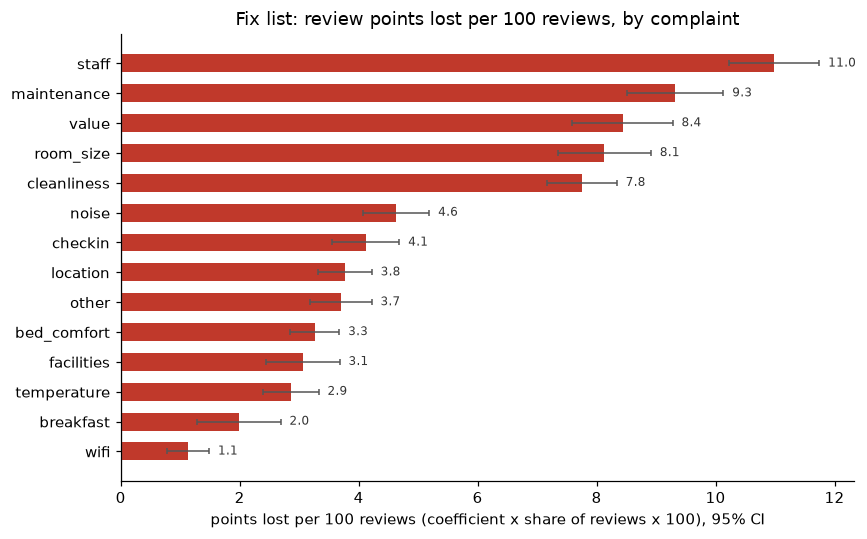

In [21]:
# The fix list as a chart: points lost per 100 reviews, with the coefficient's 95% CI carried through
t = fixes.iloc[::-1]
err = np.vstack([(t.coef - t.low95), (t.high95 - t.coef)]) * t["share of reviews"].to_numpy() * 100
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(t.index, t["points lost per 100 reviews"], color=LOW, height=0.6, xerr=err,
        error_kw={"ecolor": "#555555", "lw": 1, "capsize": 2})
for y, (v, hi) in enumerate(zip(t["points lost per 100 reviews"], err[1])):
    ax.text(max(v, 0) + hi + 0.15, y, f"{v:.1f}", va="center", fontsize=8, color="#333333")   # past the CI end
ax.axvline(0, color="#999999", lw=0.8)
ax.set(title="Fix list: review points lost per 100 reviews, by complaint",
       xlabel="points lost per 100 reviews (coefficient x share of reviews x 100), 95% CI")
plt.tight_layout(); plt.show()

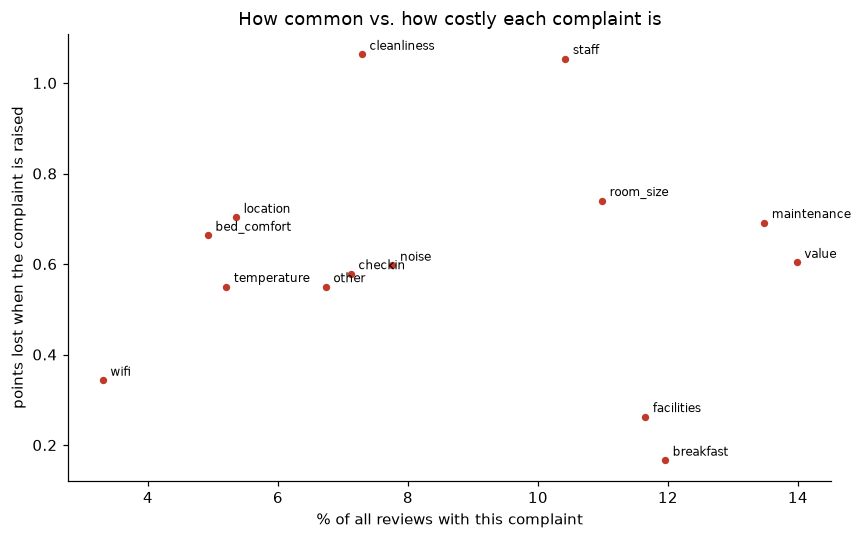

In [22]:
# How common vs. how costly (the two parts of the fix list)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fixes["share of reviews"] * 100, -fixes.coef, s=40, color=LOW, edgecolor="white", linewidth=1.5)
for cat, r in fixes.iterrows():
    ax.annotate(cat, (r["share of reviews"] * 100, -r.coef), xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.set(xlabel="% of all reviews with this complaint", ylabel="points lost when the complaint is raised",
       title="How common vs. how costly each complaint is")
plt.tight_layout(); plt.show()

In [23]:
# What earns points: praise categories (positive box)
praise = m.praise_list(m1, flags)
praise.style.format({"coef": "{:.2f}", "low95": "{:.2f}", "high95": "{:.2f}", "p": "{:.3f}",
                     "share of reviews": "{:.1%}", "points gained per 100 reviews": "{:.1f}"})

,coef,low95,high95,p,share of reviews,points gained per 100 reviews
staff,0.58,0.53,0.62,0.000,43.3%,24.9
room,0.36,0.32,0.40,0.000,30.9%,11.2
location,0.20,0.16,0.24,0.000,48.1%,9.7
other,0.76,0.70,0.82,0.000,10.7%,8.1
breakfast,0.24,0.20,0.28,0.000,20.9%,5.0
bed_comfort,0.32,0.27,0.36,0.000,15.6%,4.9
design,0.39,0.34,0.43,0.000,12.2%,4.7
facilities,0.26,0.22,0.31,0.000,13.5%,3.6
cleanliness,0.11,0.06,0.15,0.000,15.5%,1.7
checkin,0.26,0.20,0.32,0.000,5.2%,1.3


What I see.
- The top five complaints cost the most review points: staff (11.0 points per 100 reviews), maintenance (9.3), value (8.4), room size (8.1) and cleanliness (7.8). Together they are about 45 of the 73 points lost to all complaints (61%).
- Common is not the same as costly. Breakfast is mentioned in 11.9% of reviews, about as often as staff, but costs only 0.17 points when it is, so it ranks 13th. Cleanliness is mentioned less often (7.3%) but costs 1.07 points each time, as much as a staff complaint and six times a breakfast complaint.
- Staff matters at both ends: a staff complaint costs 1.05 points, and staff praise adds 0.57 points and is in 43% of reviews, so it is also the biggest source of points gained (24.9 per 100 reviews). Room praise (11.1) and location (9.6) come next.

## 6. Business vs. leisure, and cities

M1 is fit separately for each trip type and each city. A complaint needs at least 10 cases in a segment to be included. The Spearman correlation compares each segment's ranking with the overall one (1 = same order).

,segment,Spearman vs. overall,top 3 complaints
0,Business,0.85,"maintenance, staff, value"
1,Leisure,1.00,"staff, maintenance, room_size"


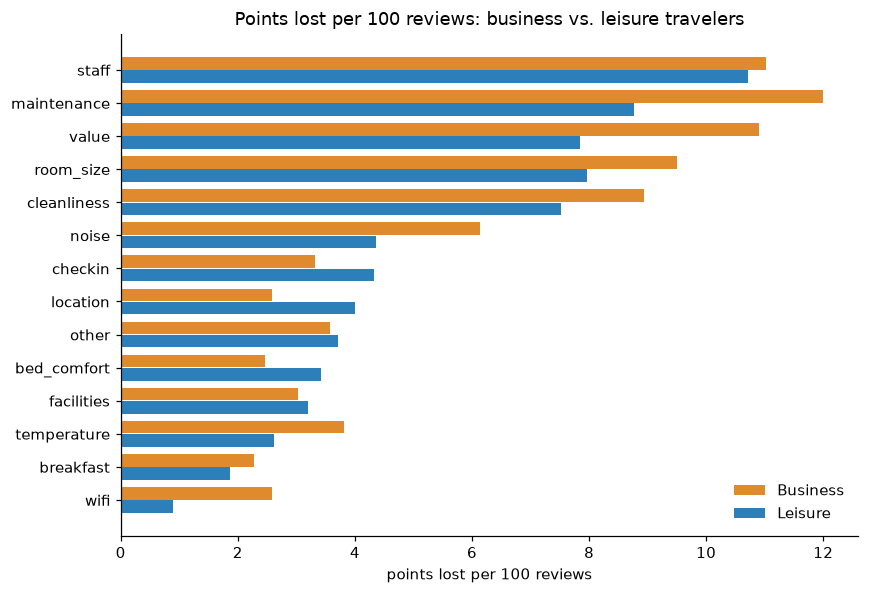

In [24]:
# Step 6: Fix list by trip type
by_trip = m.segment_fix_lists(df[df.Trip_Type != "Unknown"], X_controls, flags, "Trip_Type")
display(m.rank_agreement(fixes, by_trip).round(2))
trip = pd.DataFrame({k: v["points lost per 100 reviews"] for k, v in by_trip.items()}).reindex(fixes.index)

fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(trip))[::-1]
ax.barh(y + 0.2, trip.Business, height=0.38, color=BUSINESS, label="Business")
ax.barh(y - 0.2, trip.Leisure, height=0.38, color=LEISURE, label="Leisure")
ax.set_yticks(y, trip.index)
ax.axvline(0, color="#999999", lw=0.8)
ax.legend(frameon=False, loc="lower right")
ax.set(title="Points lost per 100 reviews: business vs. leisure travelers", xlabel="points lost per 100 reviews")
plt.tight_layout(); plt.show()

In [25]:
# Step 6.1: Fix list by city: top 3 complaints and rank agreement with the overall list
by_city = m.segment_fix_lists(df, X_controls, flags, "City")
city_table = m.rank_agreement(fixes, by_city)
city_table["reviews"] = city_table.segment.map(df.City.value_counts())
city_table.round(2)

,segment,Spearman vs. overall,top 3 complaints,reviews
0,Amsterdam,0.87,"staff, value, cleanliness",2219
1,Barcelona,0.83,"staff, value, cleanliness",2332
2,London,0.91,"maintenance, staff, room_size",10171
3,Milan,0.82,"staff, cleanliness, maintenance",1444
4,Paris,0.92,"staff, room_size, maintenance",2322
5,Vienna,0.44,"value, staff, maintenance",1510


What I see. Business and leisure travelers share the same top complaints, but business travelers punish some problems harder. Maintenance (12.0 vs. 8.8 points per 100 reviews), value (10.9 vs. 7.8), noise (6.1 vs. 4.4), temperature (3.8 vs. 2.6) and Wi-Fi (2.6 vs. 0.9) all cost more with business guests, mostly because business guests complain about them more often (Wi-Fi: 5.3% vs. 2.8% of reviews). Leisure guests are more sensitive to location and check-in. The leisure ranking is the same as the overall one (Spearman 1.00) and the business one is close (0.85). Across cities the rankings agree well (0.82 to 0.92), except Vienna (0.44), where value moves to first place. Staff is first or second in every city.

### 6.2 Bias check: native-English vs. other reviewers

The reviews are in English, so guests who write in a second language may phrase complaints differently (shorter, simpler words, unusual grammar), and Claude may label them differently. If that happens, the fix list would mostly reflect native-English guests. Three checks, comparing reviewers from the UK, US, Australia, Ireland, Canada and New Zealand with everyone else:
1. Labeling: among reviews with a complaint, do the two groups get a similar number of categories, and a similar share of `other` (Claude unsure where it fits)?
2. The fix list: fit M1 separately for each group and compare the rankings.
3. Accuracy: hand-check precision for each group (after the hand check).

In [26]:
# Step 6.2: Native-English vs. other reviewers
NATIVE = {"United Kingdom", "United States of America", "Australia", "Ireland", "Canada", "New Zealand"}
df["English_group"] = np.where(df.Reviewer_Nationality.isin(NATIVE), "native English", "other")
complained = df.has_neg == 1
n_cats = neg_flags.reindex(df.index).fillna(0)
label_rates = pd.DataFrame({
    "reviews": df.groupby("English_group").size(),
    "low-score share": df.groupby("English_group").Low_Score.mean(),
    "words in complaint (median)": df[complained].groupby("English_group").neg_words.median(),
    "categories per complaint": n_cats[complained].sum(axis=1).groupby(df.English_group[complained]).mean(),
    "share tagged 'other'": n_cats[complained]["other"].groupby(df.English_group[complained]).mean()
                            if "other" in n_cats else np.nan,
})
display(label_rates.round(3))
by_lang = m.segment_fix_lists(df, X_controls, flags, "English_group")
display(m.rank_agreement(fixes, by_lang).round(2))
lang = pd.DataFrame({k: v["points lost per 100 reviews"] for k, v in by_lang.items()}).reindex(fixes.index)
lang.round(1)

,reviews,low-score share,words in complaint (median),categories per complaint,share tagged 'other'
English_group,,,,,
native English,12726,0.154,15.0,1.737,0.099
other,7272,0.200,14.0,1.770,0.096


,segment,Spearman vs. overall,top 3 complaints
0,native English,0.99,"staff, maintenance, value"
1,other,0.93,"staff, value, room_size"


,native English,other
staff,10.2,12.4
maintenance,9.4,9.1
value,7.4,10.3
room_size,7.2,9.6
cleanliness,7.2,8.6
noise,4.8,4.3
checkin,4.8,2.9
location,3.5,4.2
other,3.8,3.3
bed_comfort,3.7,2.7


In [27]:
# Hand-check precision by group (after the hand check): are labels less accurate for non-native writers?
if FINAL and "hc_dis" in globals():
    sheet = hc.read_sheet(SHEET).set_index("review_id")
    claude_hc = bl.label_flags(records, df, "neg").loc[sheet.index]
    grp = df.loc[sheet.index, "English_group"]
    tp = ((sheet[list(bl.COMPLAINTS)] == 1) & (claude_hc == 1)).sum(axis=1)
    display(pd.DataFrame({"reviews": grp.value_counts(),
                          "precision": tp.groupby(grp).sum() / claude_hc.sum(axis=1).groupby(grp).sum()}).round(2))

,reviews,precision
English_group,,
native English,63,0.64
other,37,0.64


What I see. No sign that the labeling treats non-native English writers differently. Their complaints are about as long (median 14 vs. 15 words), get the same number of categories (1.77 vs. 1.74 per complaint), and the same share of `other` (9.6% vs. 9.9%), which would be higher if Claude struggled to place their wording. Both groups have the same top complaint (staff), and their fix lists rank almost the same (Spearman 0.99 and 0.93 with the overall list). The real difference is in the guests, not the labels: other reviewers give low scores more often (20.0% vs. 15.4%) and penalize value (10.3 vs. 7.4 points per 100 reviews) and room size (9.6 vs. 7.2) more. Hand-check precision is the same for both groups (64% for native-English and for other reviewers; recall 71% vs. 74%), so the labels are not less accurate for non-native writers.

## 7. Robustness

Four checks on the complaint coefficients:
1. Length: add the log word count of both boxes. If the coefficients shrink a lot, part of what looked like "complaint type" was just "long angry review" (Phase 2, Section 1.5).
2. Low score (below 7) as the outcome, with a logistic model: average change in the chance of a low score, in percentage points.
3. Hotel fixed effects: compares guests of the same hotel only, so a hotel that is simply worse overall can't drive the result. This is where labeling all 20K reviews (about 14 per hotel) matters.
4. Stability: refit M1 on each of the 5 training folds and compare the rankings.

In [28]:
# Step 7: Complaint coefficients under each specification
m_len = m.ols(df.Reviewer_Score, pd.concat([X1, m.length_features(df)], axis=1), df.Hotel_Name)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # some control dummies are collinear after removing hotel means; flags are not
    m_fe = m.hotel_fixed_effects(df, X1, df.Hotel_Name)
logit, margeff = m.low_score_logit(df, X1)
cats = fixes.index
robust = pd.DataFrame({
    "M1": m.coef_table(m1, "c_").coef,
    "+ length": m.coef_table(m_len, "c_").coef,
    "hotel fixed effects": m.coef_table(m_fe, "c_").coef,
    "low score, pp (logit)": margeff.loc[["c_" + c for c in cats], "dy/dx"].set_axis(cats) * 100,
}).loc[cats]
robust.round(2)

,M1,+ length,hotel fixed effects,"low score, pp (logit)"
staff,-1.05,-0.95,-1.02,13.31
maintenance,-0.69,-0.60,-0.61,9.32
value,-0.60,-0.53,-0.62,8.14
room_size,-0.74,-0.64,-0.69,10.03
cleanliness,-1.06,-0.99,-0.98,14.13
noise,-0.60,-0.49,-0.56,7.71
checkin,-0.58,-0.46,-0.56,7.20
location,-0.70,-0.59,-0.58,9.63
other,-0.55,-0.43,-0.55,7.47
bed_comfort,-0.66,-0.58,-0.58,9.14


In [29]:
# Does the ranking survive each specification? (Spearman of the coefficients with M1's)
# The logit column is a RISE in the chance of a low score, so it is flipped to point the same way as the others.
robust.assign(**{"low score, pp (logit)": -robust["low score, pp (logit)"]}).corr(method="spearman").iloc[0].round(2)

M1                       1.00
+ length                 1.00
hotel fixed effects      0.94
low score, pp (logit)    0.97
Name: M1, dtype: float64

In [30]:
# Step 7.1: Stability across folds
m.fold_stability(df, X_controls, flags, fixes).round(3)

,fold,Spearman vs. full data,top 3
0,0,0.996,"staff, maintenance, value"
1,1,1.000,"staff, maintenance, value"
2,2,0.991,"staff, maintenance, value"
3,3,0.996,"staff, maintenance, room_size"
4,4,1.000,"staff, maintenance, value"


What I see. The ranking survives every check. Adding review length shrinks the coefficients by about 10 to 25% (staff from -1.05 to -0.94), so part of each effect is "long, angry review", but the order barely moves (Spearman 0.98). Comparing only guests of the same hotel (hotel fixed effects) changes the coefficients very little (staff -1.02, cleanliness -0.98; Spearman 0.95), so the results are not just "bad hotels get more complaints". With low score (below 7) as the outcome, the same complaints matter most: a cleanliness complaint raises the chance of a low score by 14 percentage points and a staff complaint by 13 (Spearman 0.96 with M1). Across the five folds the ranking is almost identical (0.99 or higher), with staff and maintenance on top every time. Causality: these are associations. Unhappy guests may list more complaints (a halo effect), so a coefficient is an upper bound on what fixing that problem would recover.

## 8. Key findings and business implications

1. The fix list: staff (11.0 points per 100 reviews), maintenance (9.3), value (8.4), room size (8.1) and cleanliness (7.8) cost the most, together about 60% of all points lost to complaints.
2. Common is not the same as costly: breakfast is as common as staff complaints but costs 0.17 points vs. 1.05, while cleanliness is less common but just as costly as staff.
3. Business vs. leisure: same top problems, but business guests punish maintenance, value, Wi-Fi and temperature harder. Non-native English guests weigh value and room size more. Vienna is the one city with a different order.
4. Named categories vs. words: 27 categories capture 95% of what about 2,900 TF-IDF words explain, so the categories are the better tool for a manager.

What the manager should do differently:
- Start with staff: train front desk and service staff on attitude and problem handling. It is the costliest complaint and the biggest source of praise, so it moves scores in both directions.
- Fund maintenance and housekeeping before breakfast upgrades: broken or worn rooms and cleanliness cost 5 to 6 times more per complaint than breakfast does.
- For hotels with many business guests: reliable Wi-Fi, working air conditioning, and quiet rooms are cheap fixes that matter more to them.
- Track the share of reviews with each complaint by hotel each month (Claude labels cost about $0.00015 per review), and check whether fixing a problem actually moves the score.

#### Limits and possible bias
- Labels come from an LLM. Against my blind hand check of 100 reviews, precision and recall are both 64%: reliable for the top complaints (74 to 90% precision), weak for facilities (22%) and check-in (31%). Consistency was 94% on repeated reviews.
- Only guests who chose to write a review are included, Booking.com scores start at 2.5, and the data is from 2015 to 2017.
- Nationality: Section 6.2 found no sign that non-native English writers are labeled differently, but they score lower and weigh value more, so the overall fix list leans toward native-English guests (64% of reviews). Guests who wrote in other languages are not in the data at all.
- London is about half the reviews, so the overall list leans toward London (Section 6 shows each city).
- Coefficients are associations (halo effect, Section 7).

## 9. Ethical and privacy considerations

Personal information. The reviews are public, but they contain staff first names, hotel names and the reviewer's nationality. No reviewer names or accounts are in the data. Before any text went to the Claude API, spaCy NER removed person and organization names word by word (Phase 2, Section 2), so staff names never left my computer. Nationality is used only as a control in the models, never reported as a finding about a group of people. The full dataset is not in the repo, only samples.

Who is under-represented.
- Only English-language reviews are in this dataset. Guests who wrote in other languages are missing entirely, and 64% of the reviews come from native-English-speaking countries. Section 6.2 found that non-native writers are labeled just as accurately (hand-check precision 64% for both groups), but they weigh value and room size more, so the overall fix list leans toward native-English guests.
- London is about half of the reviews, so the pooled list leans toward London. Section 6 shows each city, and Vienna has a different order.
- Only guests who chose to write a review are included, and the data is from 2015 to 2017.

Who could be harmed by a wrong result.
- Staff. "Staff" is the costliest complaint. If a manager used the labels to judge individual employees, a wrong or exaggerated label could hurt someone's job. The fix list measures averages across hotels and should guide training, not discipline.
- Hotels and budgets. Claude's weakest categories (facilities 22% precision, check-in 31%) overstate those problems. Acting on them could move money away from real problems, which is why they are flagged rather than reported as findings.
- Guests whose complaints are under-counted: groups that are rare in the data, or who write in other languages, have less influence on what gets fixed.

## 10. AI usage log

All checks below follow Dr. Stefani Langehennig's AI error checks and protections (INFO 4340, Class 7): row counts before and after every step, `.describe()` / `.value_counts()` on every output, and computing each key number two ways. Each problem is reported as what went wrong, which check found it, and the fix.

| # | Task | Tool | Prompt | Output | Decision | Verification (and what went wrong) |
|---|---|---|---|---|---|---|
| 1 | Label every complaint and praise box | Claude Haiku 5.5, Batch API, low effort, JSON schema | The labeling prompt in Section 2: the category definitions, the rules for overlapping categories, "Tag every complaint category that applies" and "quote the exact words from the review that show it" | 32,290 label sets with an evidence quote for each label; 35.7M input + 2.8M output tokens, $2.48 | Used as the complaint and praise flags in every model. Facilities and check-in are reported with a warning instead of as findings. | Six automatic checks (Section 3.1), evidence quotes (99.9% found word for word), 50 repeat requests (94% identical), keyword agreement, and my blind hand check of 100 reviews (90% agreement on yes/no decisions in the random part). **Claude was wrong:** precision was only 22% for facilities and 31% for check-in. It tagged missing amenities (kettle, bathrobes, TV) as facilities complaints and "no upgrade" as a check-in problem. Caught by the blind hand check. |
| 2 | Label very long reviews | Claude Haiku 5.5, Batch API | Same prompt as row 1 | 8 answers cut off at the 1,024-token answer limit | Raised the limit to 4,096 and re-sent only those 8 requests (`submit --name full-retry`) | Every response must end normally (`end_turn`), checked when results are fetched. The check caught all 8; none were saved half-finished. |
| 3 | Test the prompt before the paid run (Phase 2) | Claude Haiku 5.5 | First version of the labeling prompt, on 12 random reviews | Labels for 12 reviews, 25 evidence quotes | Added the `facilities` category and rules for bed type and hotel-wide air conditioning to the final prompt | Compared with my own reading. Claude tagged "beds were 2 singles pushed together" as check-in and "air con broken in the bar" as temperature, both judgment errors from overlapping definitions. |
| 4 | Write and debug the Phase 3 code | Claude Code (Claude Opus 5.5) | I pasted the professor's Phase 2 feedback, then: "Yes do everything you can before the final run" | `src/batch_labels.py`, `scripts/run_batch.py`, `src/models.py`, `src/handcheck.py` and this notebook | Kept, after fixing three bugs. I ran every API call myself. | Row counts before and after each step (19,998 reviews, 32,240 non-empty boxes, 0 missing), key numbers computed twice, every output read. Found: a path bug that made the batch script read the wrong label file in a test; collinear nationality controls in the city models; and a first hand-check sheet that showed which category each review was picked for, which would have biased my labels. All three fixed before the final run. |
| 5 | Hand-check form | Claude Code | "can you actually create a word doc with each review they are hard to read on excel" | `data/handcheck_100.docx` and `scripts/handcheck_word.py`, which reads my answers back into the CSV | Used the Word form for my 100 blind labels. The labels themselves are my own judgment. | Row counts: all 100 answers read back, and any number that is not a category is reported. None found. |
| 6 | Draft findings, slides and the final report sections | Claude Code | "I just downloaded two files for the final project submission is everything done?" (with the Phase 3 instructions) | Phase 2 recap, sample outputs, trade-offs, Section 4.1, ethics, this log, the README, and slide text | Kept after every number was checked against the notebook output | Compute two ways: every number in the text recomputed from the output. Caught three wrong numbers in drafts (cleanliness 7.7 instead of 7.8 points; "1.5 to 3" instead of "1.4 to 3"; test accuracy 87.3% instead of 87.2%), all corrected. |